In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("Dataset/pizza_sales.csv")
df

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1,1,hawaiian_m,1,1/1/2015,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,1/1/2015,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,1/1/2015,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4,2,ital_supr_l,1,1/1/2015,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5,2,mexicana_m,1,1/1/2015,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza
...,...,...,...,...,...,...,...,...,...,...,...,...
48615,48616,21348,ckn_alfredo_m,1,31/12/2015,21:23:10,16.75,16.75,M,Chicken,"Chicken, Red Onions, Red Peppers, Mushrooms, A...",The Chicken Alfredo Pizza
48616,48617,21348,four_cheese_l,1,31/12/2015,21:23:10,17.95,17.95,L,Veggie,"Ricotta Cheese, Gorgonzola Piccante Cheese, Mo...",The Four Cheese Pizza
48617,48618,21348,napolitana_s,1,31/12/2015,21:23:10,12.00,12.00,S,Classic,"Tomatoes, Anchovies, Green Olives, Red Onions,...",The Napolitana Pizza
48618,48619,21349,mexicana_l,1,31/12/2015,22:09:54,20.25,20.25,L,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza


In [2]:
df.columns

Index(['pizza_id', 'order_id', 'pizza_name_id', 'quantity', 'order_date',
       'order_time', 'unit_price', 'total_price', 'pizza_size',
       'pizza_category', 'pizza_ingredients', 'pizza_name'],
      dtype='object')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pizza_id           48620 non-null  int64  
 1   order_id           48620 non-null  int64  
 2   pizza_name_id      48620 non-null  object 
 3   quantity           48620 non-null  int64  
 4   order_date         48620 non-null  object 
 5   order_time         48620 non-null  object 
 6   unit_price         48620 non-null  float64
 7   total_price        48620 non-null  float64
 8   pizza_size         48620 non-null  object 
 9   pizza_category     48620 non-null  object 
 10  pizza_ingredients  48620 non-null  object 
 11  pizza_name         48620 non-null  object 
dtypes: float64(2), int64(3), object(7)
memory usage: 4.5+ MB


In [4]:
df.describe()

,pizza_id,order_id,quantity,unit_price,total_price
count,48620.000000,48620.000000,48620.000000,48620.000000,48620.000000
mean,24310.500000,10701.479761,1.019622,16.494132,16.821474
std,14035.529381,6180.119770,0.143077,3.621789,4.437398
min,1.000000,1.000000,1.000000,9.750000,9.750000
25%,12155.750000,5337.000000,1.000000,12.750000,12.750000
50%,24310.500000,10682.500000,1.000000,16.500000,16.500000
75%,36465.250000,16100.000000,1.000000,20.250000,20.500000
max,48620.000000,21350.000000,4.000000,35.950000,83.000000


## KIP's

In [5]:
total_revenue = df['total_price'].sum()
total_pizzas_sold = df['quantity'].sum()
total_orders = df['order_id'].nunique()
avg_order_value = (total_revenue/total_orders)
avg_pizzas_per_order = (total_pizzas_sold/total_orders)



In [6]:
print(f'Total Revenue:${total_revenue:,.2f}')
print(f'Total Pizzas Sold :${total_pizzas_sold:,}')
print(f'Total Orders:${total_orders:,}')
print(f'Avg Order Value:${avg_order_value:,.2f}')
print(f'Avg Pizzas Per Order:${avg_pizzas_per_order :,.2f}')

Total Revenue:$817,860.05
Total Pizzas Sold :$49,574
Total Orders:$21,350
Avg Order Value:$38.31
Avg Pizzas Per Order:$2.32


# Ingredient Analysis

In [7]:
ingredients = (
    df['pizza_ingredients']
    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
    .reset_index()
    .rename(columns={'index':'Count','pizza_ingredients':'Ingredients'})
)
print(ingredients.head(10))

         Ingredients  count
0             Garlic  27422
1           Tomatoes  26601
2         Red Onions  19547
3        Red Peppers  16284
4  Mozzarella Cheese  10333
5          Pepperoni  10300
6            Spinach  10012
7          Mushrooms   9624
8            Chicken   8443
9          Capocollo   6572


# Daily Trend - Total Orders

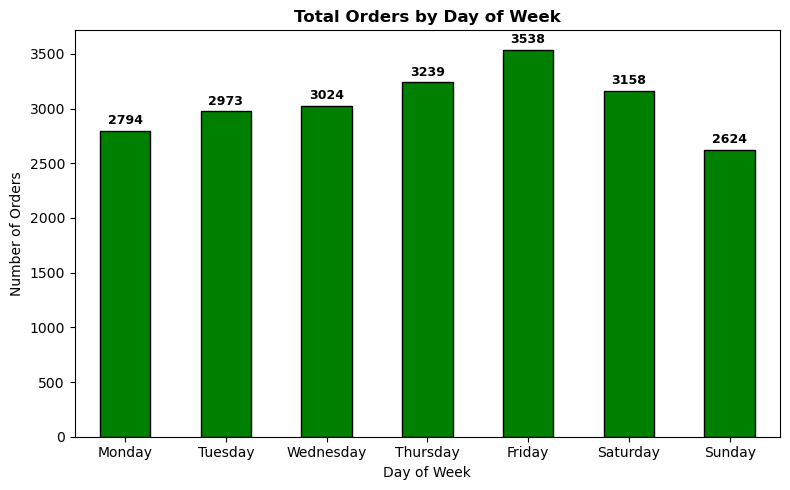

In [23]:
import pandas as pd
import matplotlib.pyplot as plt


df['order_date'] = pd.to_datetime(df['order_date'], dayfirst=True)


df['day_name'] = df['order_date'].dt.day_name()


weekday_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]


df['day_name'] = pd.Categorical(
    df['day_name'],
    categories=weekday_order,
    ordered=True
)


orders_by_day = df.groupby('day_name', observed=False)['order_id'].nunique()

# 6. Plot the bar chart
plt.figure(figsize=(8, 5))
ax = orders_by_day.plot(
    kind='bar',
    color='green',
    edgecolor='black'
)

plt.title('Total Orders by Day of Week', fontsize=12, fontweight='bold')
plt.xlabel('Day of Week', fontsize=10)
plt.ylabel('Number of Orders', fontsize=10)
plt.xticks(rotation=0)  

for i, val in enumerate(orders_by_day):
    plt.text(
        i,
        val + max(orders_by_day) * 0.01,  
        str(val),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )




plt.tight_layout()
plt.show()

# Hourly Trend - Total order

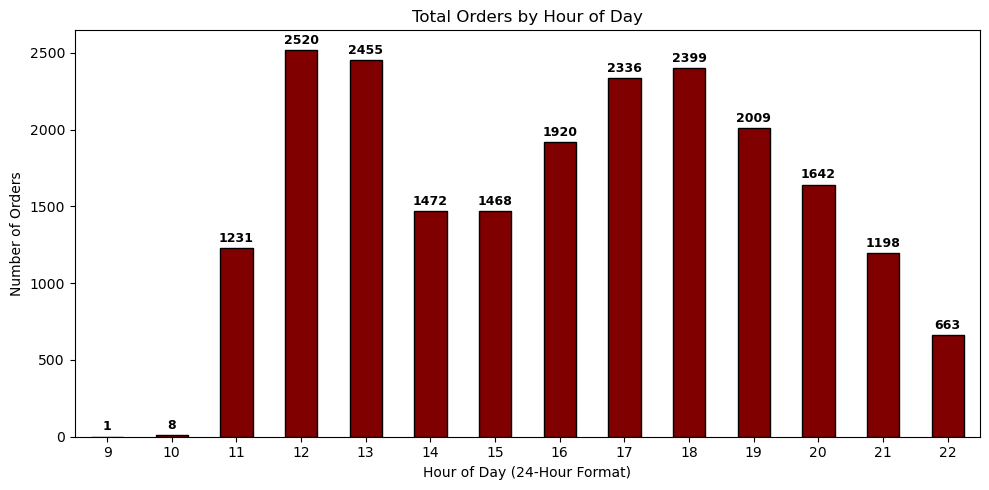

In [22]:
import pandas as pd
import matplotlib.pyplot as plt


df['order_time'] = pd.to_datetime(df['order_time'], format='%H:%M:%S')
df['order_hour'] = df['order_time'].dt.hour


orders_by_hour = df.groupby('order_hour')['order_id'].nunique()
orders_by_hour = orders_by_hour.loc[9:22]


plt.figure(figsize=(10, 5))
orders_by_hour.plot(kind='bar', color='maroon', edgecolor='black')


plt.title('Total Orders by Hour of Day')
plt.xlabel('Hour of Day (24-Hour Format)')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)


for i, val in enumerate(orders_by_hour):
    plt.text(i, val + 20, str(val), ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# Monthly Trend - Total Orders

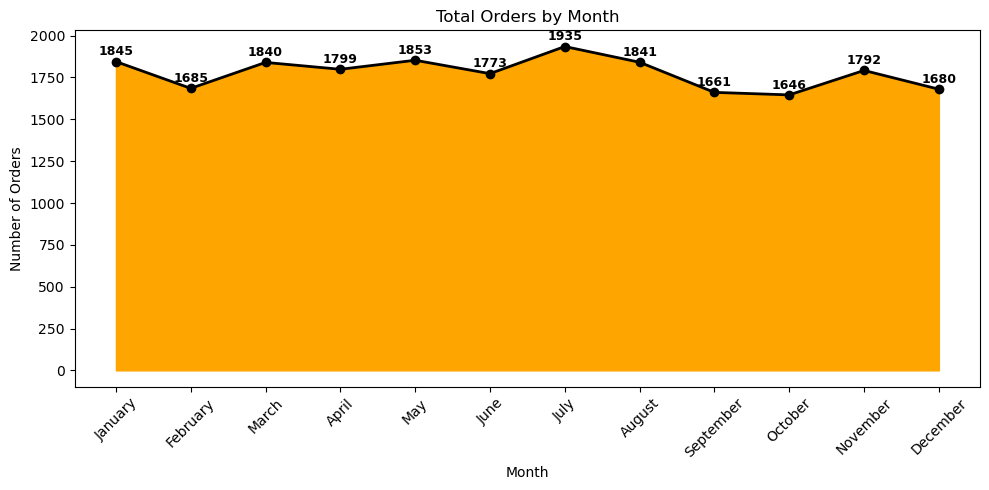

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

df['order_date'] = pd.to_datetime(df['order_date'], dayfirst=True)

df['month_name'] = df['order_date'].dt.month_name()

month_order = [
    'January',
    'February',
    'March',
    'April',
    'May',
    'June',
    'July',
    'August',
    'September',
    'October',
    'November',
    'December'
]

df['month_name'] = pd.Categorical(
    df['month_name'],
    categories=month_order,
    ordered=True
)

order_by_month = df.groupby('month_name', observed=False)['order_id'].nunique()

plt.figure(figsize=(10, 5))
plt.fill_between(order_by_month.index, order_by_month.values, color='orange',)
plt.plot(order_by_month.index, order_by_month.values, color='black', linewidth=2, marker='o')

plt.title('Total Orders by Month')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)  

# Fixed: changed orders_by_day to order_by_month
for i, val in enumerate(order_by_month):
    plt.text(
        i,
        val + 20,  
        str(val),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

In [ ]:
# % of  sales by pizza category

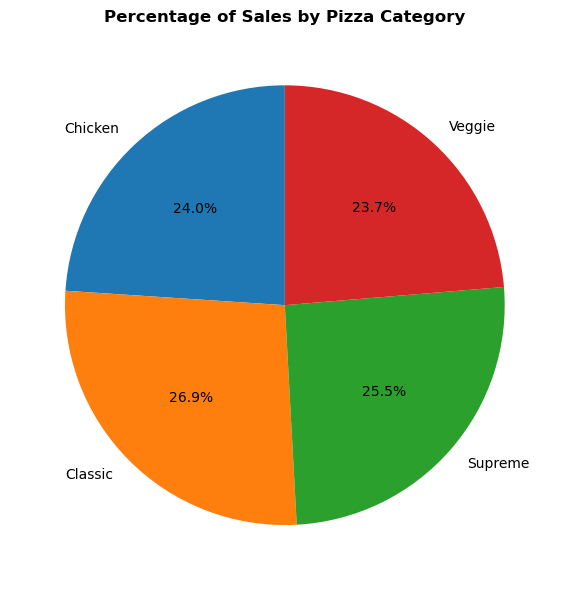

In [31]:
import pandas as pd
import matplotlib.pyplot as plt


category_sales = df.groupby('pizza_category')['total_price'].sum()
category_sales_pct = (category_sales / category_sales.sum()) * 100


plt.figure(figsize=(8, 6))
category_sales_pct.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage of Sales by Pizza Category', fontsize=12, fontweight='bold')
plt.ylabel('') 

plt.tight_layout()
plt.show()

In [ ]:
# % sales by pizza size and category sale